# Klasifikasi Hate Speech dengan XLM-RoBERTa-base

## Persiapan data


In [2]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import random
from pathlib import Path
import shutil
import tempfile
import pandas as pd
import numpy as np
import torch
import seaborn as sns
import matplotlib.pyplot as plt
from datasets import Dataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    Trainer,
    TrainingArguments,
)


In [3]:
project_dir = Path(".") if Path("data").exists() else Path("..")
input_dir = project_dir / "data"
checkpoint_dir = Path(tempfile.mkdtemp(prefix="stereoqueereval_xlmr_"))
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU tidak terdeteksi. Training dihentikan.")
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)

train_df = pd.read_excel(input_dir / "train.xlsx")[["yt_comment", "hate_speech"]]
val_df = pd.read_excel(input_dir / "val.xlsx")[["yt_comment", "hate_speech"]]
test_df = pd.read_excel(input_dir / "test.xlsx")[["yt_comment", "hate_speech"]]

label2id = {"no": 0, "yes_implicit": 1, "yes_explicit": 2}
id2label = {value: key for key, value in label2id.items()}
for data in [train_df, val_df, test_df]:
    data["text"] = data["yt_comment"].fillna("").astype(str)
    data["labels"] = data["hate_speech"].map(label2id)


GPU: NVIDIA GeForce RTX 3060 Ti
CUDA: 13.0


## Tokenisasi

In [4]:
model_name = "FacebookAI/xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)

train_data = Dataset.from_pandas(train_df[["text", "labels"]], preserve_index=False)
val_data = Dataset.from_pandas(val_df[["text", "labels"]], preserve_index=False)
test_data = Dataset.from_pandas(test_df[["text", "labels"]], preserve_index=False)

tokenize = lambda batch: tokenizer(batch["text"], truncation=True, max_length=256)
train_data = train_data.map(tokenize, batched=True, remove_columns=["text"], desc="Tokenisasi train")
val_data = val_data.map(tokenize, batched=True, remove_columns=["text"], desc="Tokenisasi val")
test_data = test_data.map(tokenize, batched=True, remove_columns=["text"], desc="Tokenisasi test")


Tokenisasi train:   0%|          | 0/5343 [00:00<?, ? examples/s]

Tokenisasi val:   0%|          | 0/763 [00:00<?, ? examples/s]

Tokenisasi test:   0%|          | 0/1521 [00:00<?, ? examples/s]

## Training

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    model_name,
    num_labels=len(label2id),
    label2id=label2id,
    id2label=id2label,
)


def compute_metrics(eval_pred):
    y_true = eval_pred.label_ids
    y_pred = np.argmax(eval_pred.predictions, axis=1)
    return {"macro_f1": f1_score(y_true, y_pred, average="macro")}

training_args = TrainingArguments(
    output_dir=str(checkpoint_dir),
    eval_strategy="epoch",
    save_strategy="epoch",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    learning_rate=2e-5,
    seed=seed,
    data_seed=seed,
    full_determinism=True,
    num_train_epochs=3,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=1,
    fp16=True,
    disable_tqdm=False,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_data,
    eval_dataset=val_data,
    data_collator=DataCollatorWithPadding(tokenizer=tokenizer),
    compute_metrics=compute_metrics,
)
print("Training device:", trainer.args.device)
if trainer.args.device.type != "cuda":
    raise RuntimeError("Trainer tidak menggunakan CUDA.")
trainer.train()
print("Best validation macro-F1:", trainer.state.best_metric)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

XLMRobertaForSequenceClassification LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training device: cuda:0


Epoch,Training Loss,Validation Loss,Macro F1
1,No log,0.954671,0.396523
2,0.978894,0.878315,0.508411
3,0.826263,0.911095,0.527304


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

Best validation macro-F1: 0.5273035800971791


## Evaluasi test

Validation loss: 0.9111
Accuracy: 0.6147
Macro F1: 0.5329
Weighted F1: 0.5835
              precision    recall  f1-score   support

          no       0.65      0.86      0.74       738
yes_implicit       0.50      0.22      0.31       367
yes_explicit       0.58      0.53      0.55       416

    accuracy                           0.61      1521
   macro avg       0.58      0.54      0.53      1521
weighted avg       0.59      0.61      0.58      1521

Checkpoint sementara dihapus.


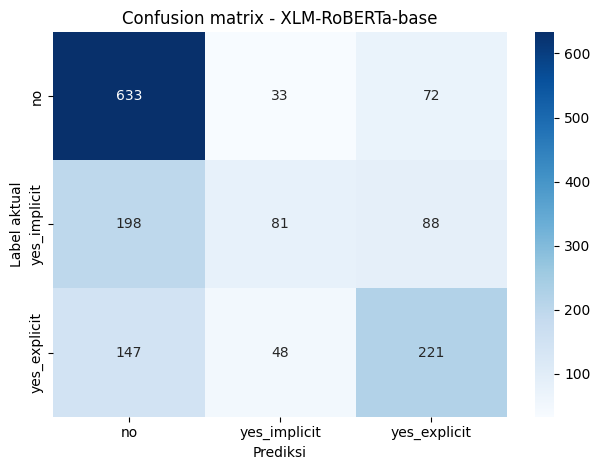

In [6]:
val_metrics = trainer.evaluate(val_data)
print("Validation loss:", round(val_metrics["eval_loss"], 4))

predictions = trainer.predict(test_data)
y_pred = predictions.predictions.argmax(axis=1)
y_true = predictions.label_ids

print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_true, y_pred, average="weighted"), 4))
print(classification_report(y_true, y_pred, target_names=list(label2id)))

matrix = confusion_matrix(y_true, y_pred)
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues",
            xticklabels=list(label2id), yticklabels=list(label2id))
plt.xlabel("Prediksi")
plt.ylabel("Label aktual")
plt.title("Confusion matrix - XLM-RoBERTa-base")
plt.tight_layout()

shutil.rmtree(checkpoint_dir, ignore_errors=True)
print("Checkpoint sementara dihapus.")
